# From PyTorch to the browser: ONNX export, FP16/INT8 quantization and temperature calibration

Live app: [https://swapnil007-curious.github.io/ManuVox/](https://swapnil007-curious.github.io/ManuVox/) · GitHub: [https://github.com/Swapnil007-Curious/ManuVox](https://github.com/Swapnil007-Curious/ManuVox) · Paper: link coming soon

ManuVox runs its sign classifier inside a browser tab with onnxruntime-web. This notebook runs every step between a trained PyTorch model and a file a web page can load: ONNX export with the feature computation inside the graph, FP16 and INT8 versions, a comparison of size, CPU latency and accuracy, and a temperature fitted on validation data so that the app's confidence scores mean what they say. The model is the CNN + Transformer hybrid from notebook 4, trained here for 40 epochs.

Data: the `asl-signs` competition files only (CC BY 4.0). Needs a GPU (T4) for training and internet for one `pip install`; about 35 minutes on Kaggle. Part 5 of a 5-notebook series.

Contents

1. Setup and a trained model
2. Export to ONNX
3. FP16 and INT8 versions
4. Size, latency and accuracy
5. Temperature calibration
6. Reliability before and after
7. Loading the model in a browser
8. What we found

## 1. Setup and a trained model

Kaggle's image ships `onnx` but not `onnxruntime`, so the first cell installs both at pinned versions (the `onnx` pin matches what Kaggle already has).

In [1]:
%pip install -q onnx==1.23.2 onnxruntime==1.31.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import math
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from cycler import cycler
from IPython.display import Image, Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Kaggle paths. The environment variables only matter when the notebook runs outside Kaggle.
INPUT_DIR = Path(os.environ.get("KAGGLE_INPUT_DIR", "/kaggle/input"))
WORK_DIR = Path(os.environ.get("KAGGLE_WORKING_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
# FAST=1 keeps a few sequences per sign, for testing the notebook end to end on a laptop.
FAST = os.environ.get("MANUVOX_FAST", "0") == "1"
FAST_PER_SIGN = 24  # Sequences per sign in FAST mode (250 signs, so about 6,000 sequences).
SEED = 42  # One seed for every random choice in the notebook.
N_WORKERS = os.cpu_count() or 1  # Kaggle gives 4 CPUs.

random.seed(SEED)
np.random.seed(SEED)

# Plot style: a colour-blind-safe categorical palette (checked for deutan, protan and tritan
# separation), one blue ramp for magnitudes, hairline grids.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.prop_cycle": cycler(color=PALETTE),
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK_2,
        "ytick.color": INK_2,
        "legend.frameon": False,
        "figure.dpi": 100,
        "font.size": 10,
    }
)


def takeaway(text):
    """Print the one-line reading of the plot above, written from this run's numbers."""
    display(Markdown(f"Takeaway: {text}"))


def save_cover(fig, name="cover.png"):
    """Save a 1280x720 copy of ``fig`` as the notebook's cover image."""
    fig.set_size_inches(12.8, 7.2)
    fig.savefig(WORK_DIR / name, dpi=100)


print(f"FAST mode: {FAST}; {N_WORKERS} CPUs")
if FAST:
    print(f"FAST is a test run on up to {FAST_PER_SIGN} sequences per sign with short training: "
          "every number below comes from that sample, not from the full data.")

FAST mode: True; 4 CPUs
FAST is a test run on up to 24 sequences per sign with short training: every number below comes from that sample, not from the full data.


In [3]:
import multiprocessing as mp

COMPETITION = "asl-signs"
# Every frame of a sequence file holds 543 rows in this order (checked on a sample below).
BLOCKS = {"face": 468, "left_hand": 21, "pose": 33, "right_hand": 21}
ROWS_PER_FRAME = sum(BLOCKS.values())
LEFT_START, POSE_START, RIGHT_START = 468, 489, 522
# Selected landmarks: left hand 0-20, right hand 0-20, then pose 0-16 (nose, eyes, ears, mouth
# corners, shoulders, elbows, wrists). The face mesh is dropped. L = 59.
POSE_POINTS = list(range(17))
SELECTED = np.r_[
    LEFT_START : LEFT_START + 21, RIGHT_START : RIGHT_START + 21, POSE_START + np.array(POSE_POINTS)
]
N_LANDMARKS = len(SELECTED)
LEFT, RIGHT = slice(0, 21), slice(21, 42)
NOSE, L_SHOULDER, R_SHOULDER, L_WRIST, R_WRIST = (42 + i for i in (0, 11, 12, 15, 16))
# Left/right pose pairs that a mirror swaps (eyes, ears, mouth corners, shoulders, elbows, wrists).
POSE_SWAP_PAIRS = [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10), (11, 12), (13, 14), (15, 16)]
NUM_FRAMES = 32  # Every sequence is resampled to this many frames.
MIN_HAND_FRAMES = 3  # Sequences with fewer frames showing a hand are dropped.
FRAME_DIM = 2 * N_LANDMARKS + 2  # x, y per landmark, then left and right hand presence.


def find_competition_dir(root=INPUT_DIR, name=COMPETITION):
    """Return the folder holding train.csv and the sign map, wherever Kaggle mounts it."""
    for candidate in (root / name, root / "competitions" / name):
        if (candidate / "train.csv").is_file():
            return candidate
    for folder, subfolders, files in os.walk(root, followlinks=True):
        subfolders[:] = [s for s in subfolders if s != "train_landmark_files"]
        if "train.csv" in files and "sign_to_prediction_index_map.json" in files:
            return Path(folder)
    raise FileNotFoundError("Add the competition data: Add Input > Competitions > asl-signs")


def load_table(data_dir, fast=FAST):
    """train.csv with integer labels; in FAST mode, up to FAST_PER_SIGN files per sign on disk."""
    table = pd.read_csv(data_dir / "train.csv", keep_default_na=False)
    sign_map = json.loads((data_dir / "sign_to_prediction_index_map.json").read_text())
    table["label"] = table["sign"].map(sign_map).astype(int)
    if fast:
        on_disk = table["path"].map(lambda p: (data_dir / p).is_file())
        table = table[on_disk].groupby("sign", sort=False).head(FAST_PER_SIGN)
    return table.reset_index(drop=True), sign_map


def check_layout(paths):
    """Confirm each file stores whole frames of 543 rows in the fixed block order."""
    types = np.repeat(list(BLOCKS), list(BLOCKS.values()))
    index = np.concatenate([np.arange(n) for n in BLOCKS.values()])
    for path in paths:
        df = pd.read_parquet(path, columns=["frame", "type", "landmark_index"])
        frames = len(df) // ROWS_PER_FRAME
        assert len(df) == frames * ROWS_PER_FRAME, f"{path.name}: partial frame"
        frame_ids = df["frame"].to_numpy().reshape(frames, ROWS_PER_FRAME)
        assert (frame_ids == frame_ids[:, :1]).all(), f"{path.name}: frames interleaved"
        assert (np.diff(frame_ids[:, 0]) > 0).all(), f"{path.name}: frames out of order"
        assert (df["type"].to_numpy().reshape(frames, -1) == types).all(), f"{path.name}: types"
        assert (df["landmark_index"].to_numpy().reshape(frames, -1) == index).all()
    return len(paths)


def read_frames(path, columns=("x", "y")):
    """All 543 landmarks of one file as a (frames, 543, len(columns)) float32 array, NaN = missing."""
    table = pq.read_table(path, columns=list(columns))
    values = [table.column(c).to_numpy().astype(np.float32) for c in columns]
    return np.stack(values, axis=-1).reshape(-1, ROWS_PER_FRAME, len(columns))


def read_xy(path):
    """The 59 selected landmarks of one file, (frames, 59, 2): x and y as fractions of the frame."""
    return read_frames(path)[:, SELECTED]


# Worker processes are forked (Linux, as on Kaggle); elsewhere the work runs in this process.
WORKERS_USED = N_WORKERS if N_WORKERS > 1 and "fork" in mp.get_all_start_methods() else 1


def parallel_map(function, items, chunksize=32):
    """Map over items with one forked process per CPU (Linux, as on Kaggle), else in a loop."""
    if WORKERS_USED > 1:
        with mp.get_context("fork").Pool(N_WORKERS) as pool:
            return list(pool.imap(function, items, chunksize=chunksize))
    return [function(item) for item in items]

In [4]:
def hand_presence(xy):
    """(frames, 2) booleans: is the left / right hand present (all 21 points finite)?"""
    finite = np.isfinite(xy).all(axis=-1)
    return np.stack([finite[:, LEFT].all(axis=1), finite[:, RIGHT].all(axis=1)], axis=1)


def mirror_permutation():
    """Landmark order after a mirror: hands swap blocks and each left/right pose pair swaps."""
    order = np.arange(N_LANDMARKS)
    order[LEFT], order[RIGHT] = np.arange(21, 42), np.arange(21)
    for a, b in POSE_SWAP_PAIRS:
        order[[42 + a, 42 + b]] = [42 + b, 42 + a]
    return order


MIRROR = mirror_permutation()


def mirror(xy):
    """Mirror a sequence: x -> 1 - x and every left/right landmark pair trades places."""
    out = xy[:, MIRROR].copy()
    out[..., 0] = 1.0 - out[..., 0]
    return out


def normalisation(xy):
    """(centre, scale): median shoulder midpoint and shoulder width; the hands if no shoulders."""
    left, right = xy[:, L_SHOULDER], xy[:, R_SHOULDER]
    both = np.isfinite(left).all(axis=1) & np.isfinite(right).all(axis=1)
    if both.any():
        centre = np.nanmedian(0.5 * (left + right), axis=0)
        width = np.hypot(left[:, 0] - right[:, 0], left[:, 1] - right[:, 1])
        return centre, float(np.nanmedian(width))
    hands = xy[:, :42].reshape(-1, 2)
    spread = np.nanmax(hands, axis=0) - np.nanmin(hands, axis=0)
    return np.nanmean(hands, axis=0), float(spread.max())


def resample(xy, num_frames=NUM_FRAMES):
    """Linear resampling over the frame index, between finite values of each coordinate only."""
    t = len(xy)
    flat = xy.reshape(t, -1).astype(np.float64)
    position = np.linspace(0.0, t - 1, num_frames)
    out = np.full((num_frames, flat.shape[1]), np.nan)
    finite = np.isfinite(flat)
    full = finite.all(axis=0)  # Columns without gaps: one vectorised interpolation.
    low = np.floor(position).astype(int)
    high = np.minimum(low + 1, t - 1)
    weight = (position - low)[:, None]
    out[:, full] = flat[low][:, full] * (1.0 - weight) + flat[high][:, full] * weight
    source = np.arange(t)
    for column in np.flatnonzero(~full & finite.any(axis=0)):
        ok = finite[:, column]
        out[:, column] = np.interp(
            position, source[ok], flat[ok, column], left=np.nan, right=np.nan
        )
    return out.reshape(num_frames, *xy.shape[1:])


def preprocess(xy):
    """Raw (frames, 59, 2) landmarks -> ((32, 120) float32 model input, info), or (None, info).

    Frames without a hand are dropped; a left-dominant sequence is mirrored so the dominant
    hand is always in the right-hand block; coordinates are centred on the shoulders and divided
    by the shoulder width; then 32 frames are resampled and missing points become 0.0.
    """
    info = {"t_raw": len(xy), "t_kept": 0, "mirrored": False}
    present = hand_presence(xy)
    keep = present.any(axis=1)
    xy, present = xy[keep], present[keep]
    info["t_kept"] = len(xy)
    if len(xy) < MIN_HAND_FRAMES:
        return None, info
    if present[:, 0].sum() > present[:, 1].sum():  # Left hand seen in more frames: mirror.
        xy, present = mirror(xy), present[:, ::-1]
        info["mirrored"] = True
    centre, scale = normalisation(xy)
    if not np.isfinite(scale) or scale < 1e-6:
        return None, info
    coords = resample((xy - centre) / scale)
    nearest = np.floor(np.linspace(0.0, len(xy) - 1, NUM_FRAMES) + 0.5).astype(int)
    frames = np.concatenate(
        [np.nan_to_num(coords, nan=0.0).reshape(NUM_FRAMES, -1), present[nearest]], axis=1
    )
    return frames.astype(np.float32), info


def _load_one(path):
    features, info = preprocess(read_xy(path))
    return (None if features is None else features.astype(np.float16)), info


def build_features(table, data_dir):
    """Preprocess every row of ``table``: returns (X float16 (n, 32, 120), kept rows, info)."""
    started = time.perf_counter()
    results = parallel_map(_load_one, [data_dir / p for p in table["path"]])
    info = pd.DataFrame([r[1] for r in results])
    kept = np.array([r[0] is not None for r in results])
    X = np.stack([r[0] for r in results if r[0] is not None])
    rows = table[kept].reset_index(drop=True)
    print(
        f"preprocessed {len(table):,} sequences in {time.perf_counter() - started:.0f} s: "
        f"{kept.sum():,} kept, {(~kept).sum():,} dropped (fewer than {MIN_HAND_FRAMES} hand frames)"
    )
    return X, rows, info.assign(kept=kept)


def signer_split(rows, n_test=4, n_val=3, seed=SEED):
    """Assign whole participants to test, val and train (the repository's seed-42 split)."""
    participants = np.random.default_rng(seed).permutation(np.unique(rows["participant_id"]))
    test, val = participants[:n_test], participants[n_test : n_test + n_val]
    split = np.where(
        rows["participant_id"].isin(test), "test", np.where(rows["participant_id"].isin(val), "val", "train")
    )
    return split, sorted(test.tolist()), sorted(val.tolist())

In [5]:
import onnx
import onnxruntime as ort
import torch
from torch import nn
from torch.nn import functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # A T4 on Kaggle; CPU works for FAST runs.
EPOCHS = 3 if FAST else 40  # Notebook 4 trains 80 epochs; this notebook is about what happens after training.
EMA_DECAY = 0.99 if FAST else 0.999
CALIBRATION_SEQUENCES = 1024  # Training sequences that set the INT8 activation ranges.
LATENCY_CALLS = 50 if FAST else 300  # Timed single-sequence calls per model.
ECE_BINS = 15
print(f"onnx {onnx.__version__}, onnxruntime {ort.__version__}, torch {torch.__version__}")

onnx 1.23.2, onnxruntime 1.31.1, torch 2.11.0+cpu


The model, augmentation and training code is the same as in notebook 4 and is collapsed here.

In [6]:
import itertools

import torch
from torch import nn
from torch.nn import functional as F

HAND_PAIRS = list(itertools.combinations(range(21), 2))  # 210 point pairs of one hand.
FINGER_POINTS = (0, 4, 8, 12, 16, 20)  # Wrist and the five fingertips.
COORDS = 2 * N_LANDMARKS  # 118 coordinates per frame.


class FeatureBlock(nn.Module):
    """(B, 32, 120) frames -> (B, 32, 588) standardised features, inside the model.

    Features: coordinates, velocity and acceleration of all 59 points, the 210 pairwise distances
    of the dominant (right-block) hand, and 24 distances from its wrist and fingertips to the
    nose, mouth centre and shoulders. A point is missing when x == y == 0, and anything derived
    from a missing point is 0. Living inside the model means the ONNX export carries it too.
    """

    def __init__(self):
        super().__init__()
        self.output_dim = 3 * COORDS + len(HAND_PAIRS) + len(FINGER_POINTS) * 4
        first, second = zip(*HAND_PAIRS)
        self.register_buffer("pair_a", torch.tensor(first) + 21, persistent=False)
        self.register_buffer("pair_b", torch.tensor(second) + 21, persistent=False)
        self.register_buffer("fingers", torch.tensor(FINGER_POINTS) + 21, persistent=False)
        face = [NOSE, 42 + 9, 42 + 10, L_SHOULDER, R_SHOULDER]  # Nose, mouth corners, shoulders.
        self.register_buffer("targets", torch.tensor(face), persistent=False)
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        second = (p[:, 2:] - 2 * p[:, 1:-1] + p[:, :-2]) * (ok[:, 2:] * ok[:, 1:-1] * ok[:, :-2]).unsqueeze(-1)
        acceleration = torch.cat([torch.zeros_like(second[:, :2]), second], dim=1)
        shape = distances(
            p.index_select(2, self.pair_a),
            p.index_select(2, self.pair_b),
            ok.index_select(2, self.pair_a) * ok.index_select(2, self.pair_b),
        )
        tg, tg_ok = p.index_select(2, self.targets), ok.index_select(2, self.targets)
        mouth = 0.5 * (tg[:, :, 1:2] + tg[:, :, 2:3])
        anchors = torch.cat([tg[:, :, :1], mouth, tg[:, :, 3:]], dim=2)
        anchors_ok = torch.cat([tg_ok[:, :, :1], tg_ok[:, :, 1:2] * tg_ok[:, :, 2:3], tg_ok[:, :, 3:]], dim=2)
        hand, hand_ok = p.index_select(2, self.fingers), ok.index_select(2, self.fingers)
        to_body = distances(
            hand.unsqueeze(3), anchors.unsqueeze(2), hand_ok.unsqueeze(3) * anchors_ok.unsqueeze(2)
        )
        return torch.cat(
            [
                x[..., :COORDS],
                velocity.reshape(b, t, COORDS),
                acceleration.reshape(b, t, COORDS),
                shape,
                to_body.reshape(b, t, -1),
            ],
            dim=-1,
        )

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


class SimpleFeatures(nn.Module):
    """Coordinates and velocity only, (B, 32, 236): the cheaper input of the temporal CNN."""

    def __init__(self):
        super().__init__()
        self.output_dim = 2 * COORDS
        self.register_buffer("mean", torch.zeros(self.output_dim))
        self.register_buffer("std", torch.ones(self.output_dim))

    def raw(self, x):
        b, t = x.shape[:2]
        p = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
        ok = ((p[..., 0] != 0) | (p[..., 1] != 0)).to(p.dtype)
        step = (p[:, 1:] - p[:, :-1]) * (ok[:, 1:] * ok[:, :-1]).unsqueeze(-1)
        velocity = torch.cat([torch.zeros_like(step[:, :1]), step], dim=1)
        return torch.cat([x[..., :COORDS], velocity.reshape(b, t, COORDS)], dim=-1)

    def forward(self, x):
        return (self.raw(x) - self.mean) / self.std.clamp_min(1e-6)


def distances(a, b, valid):
    """Euclidean distance over the last axis, 0 where ``valid`` is 0."""
    return torch.sqrt(((a - b) ** 2).sum(dim=-1)) * valid


@torch.no_grad()
def fit_standardisation(block, x_train, chunk=4096):
    """Set the block's mean and std from every frame of the train split (float64 sums)."""
    total = torch.zeros(block.output_dim, dtype=torch.float64, device=x_train.device)
    squares = torch.zeros_like(total)
    for start in range(0, len(x_train), chunk):
        values = block.raw(x_train[start : start + chunk].float()).reshape(-1, block.output_dim).double()
        total += values.sum(dim=0)
        squares += (values**2).sum(dim=0)
    count = x_train.shape[0] * x_train.shape[1]
    mean = total / count
    block.mean.copy_(mean)
    block.std.copy_((squares / count - mean**2).clamp_min(0).sqrt().clamp_min(1e-6))

In [7]:
class SelfAttention(nn.Module):
    """Multi-head self-attention written with Linear and MatMul, which export and quantise cleanly."""

    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.heads, self.head_dim = heads, dim // heads
        self.query, self.key, self.value, self.out = (nn.Linear(dim, dim) for _ in range(4))
        self.dropout = nn.Dropout(dropout)

    def split(self, x):
        return x.reshape(-1, x.shape[1], self.heads, self.head_dim).transpose(1, 2)

    def forward(self, x):
        q = self.split(self.query(x)) * self.head_dim**-0.5
        weights = torch.softmax(q @ self.split(self.key(x)).transpose(-2, -1), dim=-1)
        context = self.dropout(weights) @ self.split(self.value(x))
        return self.out(context.transpose(1, 2).flatten(2))


class TransformerBlock(nn.Module):
    """Pre-norm transformer encoder block."""

    def __init__(self, dim, heads=4, ff_dim=512, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attention = SelfAttention(dim, heads, dropout)
        self.norm2 = nn.LayerNorm(dim)
        self.ff =nn.Sequential(nn.Linear(dim, ff_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff_dim, dim))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.dropout(self.attention(self.norm1(x)))
        return x + self.dropout(self.ff(self.norm2(x)))


class ConvBlock(nn.Module):
    """Depthwise temporal conv -> BatchNorm -> SiLU -> expand -> SiLU -> project, residual. (B, C, T)."""

    def __init__(self, dim, kernel=17, expansion=512, dropout=0.2):
        super().__init__()
        self.depthwise = nn.Conv1d(dim, dim, kernel, padding=kernel // 2, groups=dim)
        self.norm = nn.BatchNorm1d(dim)
        self.expand, self.project = nn.Conv1d(dim, expansion, 1), nn.Conv1d(expansion, dim, 1)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        h = F.silu(self.norm(self.depthwise(x)))
        return x + self.dropout(self.project(F.silu(self.expand(h))))


class Stage(nn.Module):
    """Two conv blocks over time, then one transformer block. (B, T, C)."""

    def __init__(self, dim):
        super().__init__()
        self.convs = nn.Sequential(ConvBlock(dim), ConvBlock(dim))
        self.transformer = TransformerBlock(dim)

    def forward(self, x):
        return self.transformer(self.convs(x.transpose(1, 2)).transpose(1, 2))


class HybridClassifier(nn.Module):
    """Features -> linear projection -> 3 conv+transformer stages -> mean over time -> head.

    Head dropout switches on halfway through training ("late dropout").
    """

    def __init__(self, num_classes=250, dim=256, stages=3, head_dropout=0.4):
        super().__init__()
        self.features = FeatureBlock()
        self.proj = nn.Linear(self.features.output_dim, dim)
        self.stages = nn.Sequential(*(Stage(dim) for _ in range(stages)))
        self.head_dropout, self.late_dropout_on = head_dropout, False
        self.head = nn.Linear(dim, num_classes)

    def set_progress(self, epoch, epochs):
        """Called before each 1-based epoch: head dropout is on for the second half."""
        self.late_dropout_on = (epoch - 1) >= 0.5 * epochs

    def forward(self, x):
        h = self.stages(self.proj(self.features(x))).mean(dim=1)
        if self.training and self.late_dropout_on:
            h = F.dropout(h, self.head_dropout)
        return self.head(h)

In [8]:
# Per-sample probabilities. RECIPE_V2 is the repository's v2 recipe; RECIPE_V1 only the first three.
RECIPE_V1 = {"affine": 0.8, "temporal_crop": 0.5, "jitter": 0.5}
RECIPE_V2 = {**RECIPE_V1, "hand_rotation": 0.5, "frame_dropout": 0.5, "time_mask": 0.5, "landmark_mask": 0.3}


def _chosen(p, batch, gen, like):
    """Bernoulli(p) per sample, shape (B,)."""
    return torch.rand(batch, generator=gen, device=like.device) < p


def _uniform(shape, low, high, gen, like):
    return low + (high - low) * torch.rand(shape, generator=gen, device=like.device, dtype=like.dtype)


def _take_frames(values, index):
    """values[b, index[b, t]] for (B, T, ...) values and a (B, T) frame index."""
    shaped = index.reshape(*index.shape, *([1] * (values.dim() - 2)))
    return values.gather(1, shaped.expand(-1, -1, *values.shape[2:]))


def _blend(points, presence, missing, low, high, weight, nearest):
    """Linear blend of frames ``low`` and ``high``; a blend touching a missing point is missing."""
    start, end = _take_frames(points, low), _take_frames(points, high)
    gone = _take_frames(missing, low) | _take_frames(missing, high)
    blended = (start + (end - start) * weight[..., None, None]).masked_fill(gone[..., None], 0.0)
    return blended, _take_frames(presence, nearest), gone


def affine(points, missing, gen, rotate=15.0, scale=(0.85, 1.15), shift=0.1):
    """Rotate, scale and translate the whole skeleton."""
    b = points.shape[0]
    angle = _uniform((b,), -rotate, rotate, gen, points) * math.pi / 180
    size = _uniform((b,), *scale, gen, points)
    move = _uniform((b, 2), -shift, shift, gen, points)
    cos, sin = torch.cos(angle) * size, torch.sin(angle) * size
    matrix = torch.stack([torch.stack([cos, sin], -1), torch.stack([-sin, cos], -1)], -2)
    out = torch.einsum("btlc,bcd->btld", points, matrix) + move[:, None, None]
    return out.masked_fill(missing[..., None], 0.0)


def hand_rotation(points, missing, gen, degrees=10.0):
    """Rotate each hand about its own wrist by its own angle."""
    out = points.clone()
    angle = _uniform((points.shape[0], 2), -degrees, degrees, gen, points) * math.pi / 180
    for h, block in enumerate((LEFT, RIGHT)):
        cos, sin = torch.cos(angle[:, h])[:, None, None], torch.sin(angle[:, h])[:, None, None]
        hand = points[:, :, block]
        offset = hand - hand[:, :, :1]
        turned = hand[:, :, :1] + torch.stack(
            [offset[..., 0] * cos - offset[..., 1] * sin, offset[..., 0] * sin + offset[..., 1] * cos], -1
        )
        ok = ~missing[:, :, block] & ~missing[:, :, block][:, :, :1]
        out[:, :, block] = torch.where(ok[..., None], turned, hand)
    return out


def temporal_crop(points, presence, missing, gen, window_min=0.8):
    """Keep a random window of 80-100% of the sequence and stretch it back to 32 frames."""
    b, t = points.shape[:2]
    last = t - 1
    length = _uniform((b,), window_min, 1.0, gen, points) * last
    offset = _uniform((b,), 0.0, 1.0, gen, points) * (last - length)
    steps = torch.arange(t, device=points.device, dtype=points.dtype)
    position = (offset[:, None] + steps * (length / last)[:, None]).clamp(0, last)
    low = position.floor().long()
    weight = position - low
    high = torch.where(weight > 0, low + 1, low).clamp(max=last)
    return _blend(points, presence, missing, low, high, weight, (position + 0.5).floor().long().clamp(max=last))


def frame_dropout(points, presence, missing, gen, max_fraction=0.2):
    """Drop up to 20% of the frames at random and stretch the rest back to 32 frames."""
    b, t = points.shape[:2]
    n_drop = (_uniform((b,), 0.0, max_fraction, gen, points) * t).floor().long().clamp(max=t - 2)
    rank = torch.rand((b, t), generator=gen, device=points.device).argsort(1).argsort(1)
    steps = torch.arange(t, device=points.device)
    kept_order = torch.where(rank < n_drop[:, None], steps + t, steps).argsort(1)  # Kept frames first.
    last_kept = (t - 1 - n_drop)[:, None]
    position = steps[None].to(points.dtype) * (last_kept.to(points.dtype) / (t - 1))
    low = position.floor().long()
    weight = position - low
    high = torch.minimum(torch.where(weight > 0, low + 1, low), last_kept)
    nearest = torch.minimum((position + 0.5).floor().long(), last_kept)
    source = lambda index: kept_order.gather(1, index)  # noqa: E731
    return _blend(points, presence, missing, source(low), source(high), weight, source(nearest))


def time_mask(points, presence, missing, gen, windows=2, max_frames=4):
    """Blank one or two short windows of 1-4 frames."""
    b, t = points.shape[:2]
    dev = points.device
    count = torch.randint(1, windows + 1, (b,), generator=gen, device=dev)
    length = torch.randint(1, max_frames + 1, (b, windows), generator=gen, device=dev)
    start = (torch.rand((b, windows), generator=gen, device=dev) * (t - length + 1)).floor().long()
    steps = torch.arange(t, device=dev)[None, None]
    used = torch.arange(windows, device=dev)[None, :, None] < count[:, None, None]
    blank = ((steps >= start[..., None]) & (steps < (start + length)[..., None]) & used).any(1)
    return points.masked_fill(blank[..., None, None], 0.0), presence.masked_fill(blank[..., None], 0.0), missing | blank[..., None]


def landmark_mask(points, presence, missing, gen, max_points=4):
    """Hide 1-4 random landmarks (never a wrist) for the whole sequence."""
    b, _, n = points.shape[:3]
    dev = points.device
    count = torch.randint(1, max_points + 1, (b,), generator=gen, device=dev)
    scores = torch.rand((b, n), generator=gen, device=dev)
    scores[:, [LEFT.start, RIGHT.start]] = 2.0  # Wrists sort last, so they are never picked.
    hidden = scores.argsort(1).argsort(1) < count[:, None]
    return points.masked_fill(hidden[:, None, :, None], 0.0), presence, missing | hidden[:, None]


def jitter(points, missing, gen, std=0.01):
    """Add Gaussian noise to every visible point."""
    noise = torch.randn(points.shape, generator=gen, device=points.device, dtype=points.dtype)
    return (points + std * noise).masked_fill(missing[..., None], 0.0)


# Every transform maps (points, presence, missing, gen) to new (points, presence, missing).
TRANSFORMS = {
    "affine": lambda p, pr, m, g: (affine(p, m, g), pr, m),
    "hand_rotation": lambda p, pr, m, g: (hand_rotation(p, m, g), pr, m),
    "temporal_crop": temporal_crop,
    "frame_dropout": frame_dropout,
    "jitter": lambda p, pr, m, g: (jitter(p, m, g), pr, m),
    "time_mask": time_mask,
    "landmark_mask": landmark_mask,
}


def _where(chosen, new, old):
    """Per-sample choice between two tensors whose first axis is the batch."""
    return torch.where(chosen.reshape(-1, *([1] * (old.dim() - 1))), new, old)


def augment_batch(x, recipe, gen):
    """Apply the recipe to a (B, 32, 120) batch, in the order of TRANSFORMS; missing points stay 0."""
    b, t = x.shape[:2]
    points = x[..., :COORDS].reshape(b, t, N_LANDMARKS, 2)
    presence, missing = x[..., COORDS:], (points == 0).all(-1)
    for name, transform in TRANSFORMS.items():
        if name in recipe:
            chosen = _chosen(recipe[name], b, gen, x)
            new = transform(points, presence, missing, gen)
            points, presence, missing = (_where(chosen, n, o) for n, o in zip(new, (points, presence, missing)))
    return torch.cat([points.reshape(b, t, COORDS), presence], dim=-1)

In [9]:
import copy


def seed_torch(seed=SEED):
    """Seed torch on every device. GPU kernels can still differ bitwise between runs."""
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False


class EMA:
    """A frozen copy whose weights follow ema = decay * ema + (1 - decay) * live after each step."""

    def __init__(self, model, decay):
        self.decay = decay
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        for avg, live in zip(self.module.parameters(), model.parameters()):
            avg.lerp_(live.detach(), 1.0 - self.decay)
        for stored, current in zip(self.module.buffers(), model.buffers()):
            stored.copy_(current)


def warmup_cosine(total_steps, warmup_fraction=0.05):
    """LR multiplier per step: linear warmup, then cosine decay to zero."""
    warmup = max(1, round(total_steps * warmup_fraction))

    def factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warmup) / max(1, total_steps - warmup))))

    return factor


@torch.no_grad()
def predict_logits(model, x, batch_size=1024):
    """Float32 logits in eval mode, in batches."""
    model.eval()
    return torch.cat([model(x[i : i + batch_size].float()).float() for i in range(0, len(x), batch_size)])


def top_k(logits, y, k=1):
    """Share of rows whose label is among the k highest logits."""
    return (logits.topk(k, dim=1).indices == y[:, None]).any(dim=1).float().mean().item()


def train_model(model, x_train, y_train, x_val=None, y_val=None, *, epochs, lr, recipe,
                batch_size=256, weight_decay=0.05, label_smoothing=0.1, ema_decay=None,
                patience=None, seed=SEED, quiet=False):
    """Train with AdamW, warmup + cosine LR and mixed precision on GPU.

    With validation data, the epoch with the best val top-1 is kept (EMA weights when
    ``ema_decay`` is set); without it, the last epoch is kept. Returns (model, history).
    """
    seed_torch(seed)
    model = model.to(DEVICE)
    fit_standardisation(model.features, x_train)
    ema = EMA(model, ema_decay) if ema_decay else None
    scored = ema.module if ema else model
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(x_train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, warmup_cosine(epochs * steps_per_epoch))
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    order_gen = torch.Generator().manual_seed(seed)
    augment_gen = torch.Generator(device=DEVICE).manual_seed(seed + 1)
    history, best, best_state, stale = [], -1.0, None, 0
    report_every = max(1, epochs // 10)
    for epoch in range(1, epochs + 1):
        started = time.perf_counter()
        model.train()
        model.set_progress(epoch, epochs)
        order = torch.randperm(len(x_train), generator=order_gen).to(DEVICE)
        loss_sum, correct = torch.zeros((), device=DEVICE), torch.zeros((), device=DEVICE)
        for i in range(0, len(order), batch_size):
            index = order[i : i + batch_size]
            batch, target = augment_batch(x_train[index].float(), recipe, augment_gen), y_train[index]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(batch)
                loss = criterion(logits, target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            if ema:
                ema.update(model)
            loss_sum += loss.detach().float() * len(index)
            correct += (logits.argmax(1) == target).sum()
        row = {"epoch": epoch, "train_loss": loss_sum.item() / len(order), "train_top1": correct.item() / len(order)}
        if x_val is not None:
            row["val_top1"] = top_k(predict_logits(scored, x_val), y_val)
        row["seconds"] = time.perf_counter() - started
        history.append(row)
        improved = x_val is None or row["val_top1"] > best
        if improved:
            best, stale = row.get("val_top1", best), 0
            best_state = copy.deepcopy(scored.state_dict())
        else:
            stale += 1
        if not quiet and (epoch % report_every == 0 or epoch == 1 or epoch == epochs):
            val = f", val top-1 {row['val_top1']:.3f}" if x_val is not None else ""
            print(f"epoch {epoch:3d}/{epochs}: train loss {row['train_loss']:.3f}, "
                  f"train top-1 {row['train_top1']:.3f}{val} ({row['seconds']:.1f} s)")
        if patience and stale >= patience:
            print(f"early stop after epoch {epoch}: no val gain for {patience} epochs")
            break
    scored.load_state_dict(best_state)
    return scored.eval(), pd.DataFrame(history)


def bootstrap_ci(values, n_boot=1000, seed=SEED):
    """95% percentile interval of the mean of ``values`` (1-D), resampling rows."""
    values = np.asarray(values, dtype=np.float64)
    rng = np.random.default_rng(seed)
    means = np.array([values[rng.integers(0, len(values), len(values))].mean() for _ in range(n_boot)])
    return np.percentile(means, [2.5, 97.5])

In [10]:
DATA_DIR = find_competition_dir()
table, sign_map = load_table(DATA_DIR)
X, rows, _ = build_features(table, DATA_DIR)
split, test_signers, val_signers = signer_split(rows)
y_all = rows["label"].to_numpy()
data = {name: (X[split == name].astype(np.float32), y_all[split == name]) for name in ("train", "val", "test")}
print({name: len(y) for name, (_, y) in data.items()})

to_gpu = lambda name: (torch.from_numpy(data[name][0]).to(DEVICE), torch.from_numpy(data[name][1]).long().to(DEVICE))  # noqa: E731
model, history = train_model(HybridClassifier(), *to_gpu("train"), *to_gpu("val"), epochs=EPOCHS, lr=5e-4,
                             recipe=RECIPE_V2, ema_decay=EMA_DECAY)
model = model.cpu().eval()
print(f"best val top-1 {history['val_top1'].max():.3f}")

preprocessed 6,000 sequences in 23 s: 5,536 kept, 464 dropped (fewer than 3 hand frames)
{'train': 3725, 'val': 805, 'test': 1006}


epoch   1/3: train loss 5.228, train top-1 0.040, val top-1 0.005 (61.5 s)


epoch   2/3: train loss 4.315, train top-1 0.158, val top-1 0.031 (58.4 s)


epoch   3/3: train loss 4.271, train top-1 0.138, val top-1 0.062 (60.8 s)
best val top-1 0.062


## 2. Export to ONNX

The export traces the model with a dummy batch and writes a graph with one input, `landmarks` (batch, 32, 120), and one output, `logits` (batch, 250). The batch axis is dynamic. Because the feature block and its standardisation statistics are part of the model, the browser feeds raw landmarks and nothing has to be reimplemented in JavaScript. The legacy TorchScript exporter (`dynamo=False`) is used because it needs no extra packages and handles this model's plain ops.

In [11]:
def export_onnx(model, path):
    """Export with a dynamic batch axis at opset 17, then run the ONNX checker."""
    example = torch.zeros(2, NUM_FRAMES, FRAME_DIM)  # Batch 2, so the tracer cannot fold the batch size.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message=".*legacy TorchScript-based ONNX export.*")
        warnings.filterwarnings("ignore", message=".*will be removed.*")
        torch.onnx.export(model, (example,), str(path), input_names=["landmarks"], output_names=["logits"],
                          dynamic_axes={"landmarks": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17, dynamo=False)
    onnx.checker.check_model(str(path))
    return path


def session(path, threads=1):
    """A CPU onnxruntime session with a fixed thread count and full graph optimisation."""
    options = ort.SessionOptions()
    options.intra_op_num_threads = threads
    options.inter_op_num_threads = 1
    options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    options.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    options.log_severity_level = 3
    return ort.InferenceSession(str(path), options, providers=["CPUExecutionProvider"])


def onnx_logits(path, x, batch=512):
    """Logits from an ONNX file for a float32 array of frames."""
    s = session(path, threads=N_WORKERS)
    return np.concatenate([s.run(["logits"], {"landmarks": x[i : i + batch]})[0] for i in range(0, len(x), batch)])


MODELS = {"fp32": export_onnx(model, WORK_DIR / "model_fp32.onnx")}
x_check = data["val"][0][:256]
with torch.no_grad():
    reference = model(torch.from_numpy(x_check)).numpy()
exported = onnx_logits(MODELS["fp32"], x_check)
print(f"PyTorch vs ONNX on 256 val sequences: max |logit difference| {np.abs(reference - exported).max():.2e}, "
      f"top-1 agreement {(reference.argmax(1) == exported.argmax(1)).mean():.1%}")

PyTorch vs ONNX on 256 val sequences: max |logit difference| 9.54e-07, top-1 agreement 100.0%


## 3. FP16 and INT8 versions

Four smaller versions of the same graph:

- FP16: weights and arithmetic in half precision, input and output kept in float32. If its top-1 agreement with FP32 on validation falls below 99%, it is rebuilt with the feature block kept in float32.
- INT8 dynamic: weights stored as 8-bit integers per channel, activations quantised on the fly at run time.
- INT8 static: weights and activations both 8-bit, with activation ranges measured on 1,024 training sequences (the calibration set; validation and test are never used). The feature block is excluded, so raw coordinates, velocity and standardisation stay float32 and quantisation starts at the first projection layer.
- INT8 static, full: the same with nothing excluded, as an ablation. Quantising the raw input rounds coordinates onto an 8-bit grid before velocity is computed, and can turn small coordinates into exact zeros, which the feature block reads as missing points.

The FP16 and static recipes follow the repository's `src/edgevision/quant/variants.py`.

In [12]:
from onnxruntime.quantization import CalibrationMethod, QuantFormat, QuantType, quantize_dynamic, quantize_static
from onnxruntime.quantization.shape_inference import quant_pre_process
from onnxruntime.transformers.float16 import convert_float_to_float16
from onnxruntime.transformers.onnx_model import OnnxModel

FEATURE_SCOPE = "/features/"  # Exporter name prefix of every node inside model.features.


def feature_nodes(path):
    """Names of the nodes that compute the feature block."""
    return [n.name for n in onnx.load(str(path)).graph.node if n.name.startswith(FEATURE_SCOPE)]


def to_fp16(src, dst, keep_features_fp32=False):
    """Half-precision weights and compute, float32 input and output."""
    converted = convert_float_to_float16(onnx.load(str(src)), keep_io_types=True,
                                         node_block_list=feature_nodes(src) if keep_features_fp32 else None)
    seen, unique = set(), []
    for node in converted.graph.node:  # A block list can add byte-identical Cast nodes; keep one of each.
        key = node.SerializeToString(deterministic=True)
        if key not in seen:
            seen.add(key)
            unique.append(node)
    converted.graph.ClearField("node")
    converted.graph.node.extend(unique)
    OnnxModel.graph_topological_sort(converted.graph)
    onnx.save(converted, str(dst))
    onnx.checker.check_model(str(dst))
    return dst


class CalibrationReader:
    """Feeds quantize_static a fixed random sample of training sequences, 64 at a time."""

    def __init__(self, x, n=CALIBRATION_SEQUENCES, batch=64, seed=SEED):
        rows_ = np.sort(np.random.default_rng(seed).choice(len(x), size=min(n, len(x)), replace=False))
        self.x, self.batch, self.position = x[rows_], batch, 0

    def get_next(self):
        if self.position >= len(self.x):
            return None
        chunk = self.x[self.position : self.position + self.batch]
        self.position += self.batch
        return {"landmarks": chunk}

    def rewind(self):
        self.position = 0


def to_int8_static(src, dst, exclude_features=True):
    """Static QDQ quantisation: uint8 activations, int8 per-channel weights, MinMax ranges."""
    prepared = dst.with_name(dst.stem + "_prepared.onnx")
    quant_pre_process(str(src), str(prepared))
    quantize_static(str(prepared), str(dst), CalibrationReader(data["train"][0]),
                    quant_format=QuantFormat.QDQ, activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8,
                    per_channel=True, reduce_range=False, calibrate_method=CalibrationMethod.MinMax,
                    nodes_to_exclude=feature_nodes(prepared) if exclude_features else [])
    prepared.unlink()
    return dst

In [13]:
started = time.perf_counter()
x_val, y_val = data["val"]
fp32_val = onnx_logits(MODELS["fp32"], x_val).argmax(1)
MODELS["fp16"] = to_fp16(MODELS["fp32"], WORK_DIR / "model_fp16.onnx")
fp16_agreement = (onnx_logits(MODELS["fp16"], x_val).argmax(1) == fp32_val).mean()
if fp16_agreement < 0.99:
    print(f"FP16 agreement {fp16_agreement:.2%} < 99%: rebuilding with the feature block in float32")
    MODELS["fp16"] = to_fp16(MODELS["fp32"], WORK_DIR / "model_fp16.onnx", keep_features_fp32=True)
    fp16_agreement = (onnx_logits(MODELS["fp16"], x_val).argmax(1) == fp32_val).mean()
print(f"FP16 top-1 agreement with FP32 on validation: {fp16_agreement:.2%}")

import logging

# The quantiser warns about shape inference on every run, and logs one line per LayerNorm weight
# it cannot quantise per channel (those weights are 1-D and stay float). Both are expected here.
root_logger, root_level = logging.getLogger(), logging.getLogger().level
root_logger.setLevel(logging.ERROR)
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        quantize_dynamic(str(MODELS["fp32"]), str(WORK_DIR / "model_int8_dynamic.onnx"), weight_type=QuantType.QInt8, per_channel=True)
        MODELS["int8 dynamic"] = WORK_DIR / "model_int8_dynamic.onnx"
        MODELS["int8 static"] = to_int8_static(MODELS["fp32"], WORK_DIR / "model_int8_static.onnx")
        MODELS["int8 static, full"] = to_int8_static(MODELS["fp32"], WORK_DIR / "model_int8_static_full.onnx", exclude_features=False)
finally:
    root_logger.setLevel(root_level)
print(f"built {len(MODELS) - 1} variants in {time.perf_counter() - started:.0f} s")

FP16 top-1 agreement with FP32 on validation: 99.88%


built 4 variants in 21 s


## 4. Size, latency and accuracy

Latency is one sequence per call on one CPU thread, the way a browser worker calls the model: 20 warm-up calls, then timed calls with `time.perf_counter`. It is measured on whatever CPU runs the notebook (Kaggle's, when it runs there), so absolute numbers will differ on a laptop; the ratios between versions are the useful part. Accuracy is test top-1 on the four unseen signers, and agreement is the share of test clips where a version predicts the same sign as FP32.

In [14]:
def cpu_name():
    """The CPU model: /proc/cpuinfo on Linux (Kaggle), the registry on Windows, else the platform module."""
    try:
        for line in Path("/proc/cpuinfo").read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    try:
        import winreg

        key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
    except (ImportError, OSError):
        import platform

        return platform.processor() or "unknown CPU"


def pts(value):
    """Signed percentage points with one decimal; zero is written as 0.0, never +0.0 or -0.0."""
    text = f"{value:+.1f}"
    return "0.0" if text.lstrip("+-") == "0.0" else text


CPU = cpu_name()
print(f"latency measured on: {CPU}")


def latency_ms(path, x, calls=LATENCY_CALLS, warmup=20):
    """p50 and p95 milliseconds of single-sequence calls on one thread."""
    s = session(path, threads=1)
    times = []
    for i in range(warmup + calls):
        sample = x[i % len(x)][None]
        started = time.perf_counter()
        s.run(["logits"], {"landmarks": sample})
        if i >= warmup:
            times.append(1000 * (time.perf_counter() - started))
    return np.percentile(times, 50), np.percentile(times, 95)


x_test, y_test = data["test"]
test_logits = {name: onnx_logits(path, x_test) for name, path in MODELS.items()}
report = []
for name, path in MODELS.items():
    p50, p95 = latency_ms(path, x_val)
    predicted = test_logits[name].argmax(1)
    report.append({"version": name, "size_mb": path.stat().st_size / 1e6, "p50_ms": p50, "p95_ms": p95,
                   "test_top1": (predicted == y_test).mean(), "agreement_with_fp32": (predicted == test_logits["fp32"].argmax(1)).mean()})
report = pd.DataFrame(report).set_index("version")
report["delta_top1_pts"] = 100 * (report["test_top1"] - report.loc["fp32", "test_top1"])
report.round(3)

latency measured on: 11th Gen Intel(R) Core(TM) i3-1115G4 @ 3.00GHz


,size_mb,p50_ms,p95_ms,test_top1,agreement_with_fp32,delta_top1_pts
version,,,,,,
fp32,13.697,3.769,5.164,0.083,1.000,0.000
fp16,6.925,3.763,4.489,0.083,1.000,0.000
int8 dynamic,3.658,22.378,24.745,0.080,0.837,-0.398
int8 static,3.795,1.817,2.626,0.086,0.682,0.298
"int8 static, full",3.825,1.871,2.738,0.083,0.705,-0.099


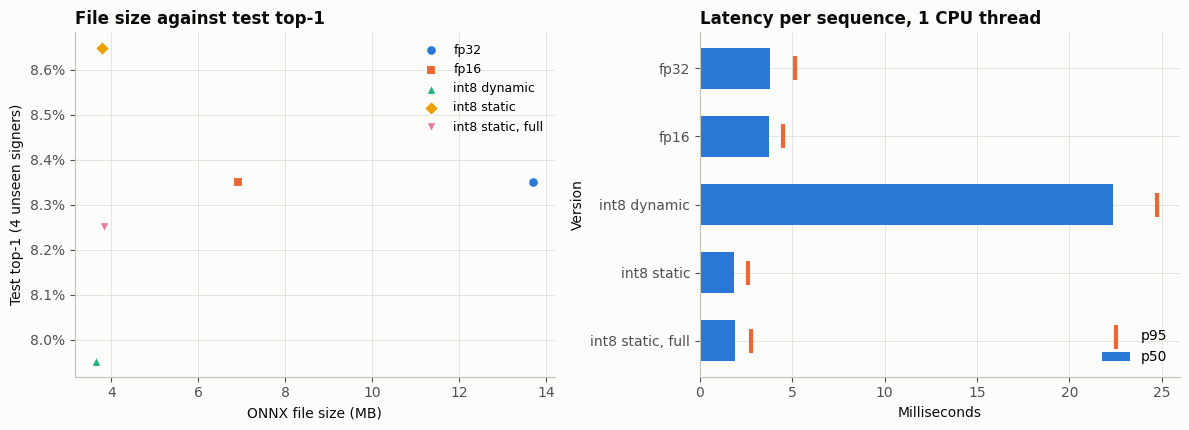

Takeaway: FP16 halves the file (13.7 to 6.9 MB) and changes test top-1 by 0.0 points; the smallest file, int8 dynamic at 3.7 MB, changes it by -0.4 points, and INT8 static with the input quantised by -0.1 points.

In [15]:
from matplotlib.ticker import PercentFormatter

MARKERS = ["o", "s", "^", "D", "v"]  # One colour and one marker per version, so close points stay readable.


def size_accuracy(ax, size=60, fontsize=9):
    """Each version as its own point (colour + marker), identified in a legend."""
    for (name, row), colour, marker in zip(report.iterrows(), PALETTE, MARKERS):
        ax.scatter(row["size_mb"], row["test_top1"], color=colour, marker=marker, s=size, zorder=3,
                   edgecolor=SURFACE, linewidth=1.5, label=name)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
    ax.legend(loc="best", fontsize=fontsize)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4))
size_accuracy(ax1)
ax1.set(title="File size against test top-1", xlabel="ONNX file size (MB)", ylabel="Test top-1 (4 unseen signers)")
y = np.arange(len(report))
ax2.barh(y, report["p50_ms"], color=BLUE, height=0.6, label="p50")
ax2.scatter(report["p95_ms"], y, color=ORANGE, marker="|", s=300, linewidth=3, zorder=3, label="p95")
ax2.set_yticks(y, report.index)
ax2.invert_yaxis()
ax2.set(title="Latency per sequence, 1 CPU thread", xlabel="Milliseconds", ylabel="Version")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()
smallest = report["size_mb"].idxmin()
takeaway(f"FP16 halves the file ({report.loc['fp32', 'size_mb']:.1f} to {report.loc['fp16', 'size_mb']:.1f} MB) and changes test top-1 "
         f"by {pts(report.loc['fp16', 'delta_top1_pts'])} points; the smallest file, {smallest} at {report.loc[smallest, 'size_mb']:.1f} MB, "
         f"changes it by {pts(report.loc[smallest, 'delta_top1_pts'])} points, and INT8 static with the input quantised by "
         f"{pts(report.loc['int8 static, full', 'delta_top1_pts'])} points.")

The repository ran the same comparison on its earlier models. On its temporal CNN (mean of three seeds), FP16 had the same test top-1 as FP32, INT8 dynamic lost 3.1 points and INT8 static 6.8 points (`results/tables/test_quant_summary.csv`). It shipped the FP16 hybrid, a 6.9 MB file that runs in 18.1 ms at p50 in Chrome on an i3-1115G4 laptop (`results/model_selection.md`).

## 5. Temperature calibration

The app shows a sign only when the model is confident enough, so its confidence has to be honest: of all predictions made at 80% confidence, about 80% should be right. Temperature scaling divides the logits by one number T before the softmax. It never changes which sign ranks first, only how sure the model claims to be. T is fitted on the validation signers by minimising the negative log-likelihood, and judged on the test signers with the expected calibration error (ECE): the confidence-weighted gap between confidence and accuracy over 15 equal-width bins.

The FP16 model is calibrated, because that is the version a browser would load.

In [16]:
def log_softmax(logits, t=1.0):
    z = logits / t
    z = z - z.max(axis=1, keepdims=True)
    return z - np.log(np.exp(z).sum(axis=1, keepdims=True))


def nll(logits, y, t=1.0):
    """Mean negative log-likelihood of the true labels under softmax(logits / t)."""
    return float(-log_softmax(logits, t)[np.arange(len(y)), y].mean())


def fit_temperature(logits, y, low=0.05, high=20.0):
    """The temperature minimising NLL, by golden-section search on log t."""
    a, b = np.log(low), np.log(high)
    ratio = (np.sqrt(5) - 1) / 2
    for _ in range(80):
        c, d = b - ratio * (b - a), a + ratio * (b - a)
        if nll(logits, y, np.exp(c)) < nll(logits, y, np.exp(d)):
            b = d
        else:
            a = c
    return float(np.exp((a + b) / 2))


def reliability(logits, y, t=1.0, bins=ECE_BINS):
    """Per-bin (mean confidence, accuracy, count) of the top-1 prediction, and the ECE."""
    p = np.exp(log_softmax(logits, t))
    confidence, correct = p.max(axis=1), p.argmax(axis=1) == y
    which = np.clip(np.digitize(confidence, np.linspace(0, 1, bins + 1)[1:-1], right=True), 0, bins - 1)
    table = pd.DataFrame({"bin": which, "confidence": confidence, "correct": correct}).groupby("bin").agg(
        confidence=("confidence", "mean"), accuracy=("correct", "mean"), count=("correct", "size"))
    ece = float((table["count"] / len(y) * (table["accuracy"] - table["confidence"]).abs()).sum())
    return table, ece


def ece_ci(logits, y, t, n_boot=200, seed=SEED):
    """95% bootstrap interval of the ECE, resampling test clips."""
    rng = np.random.default_rng(seed)
    values = [reliability(logits[i], y[i], t)[1] for i in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return np.percentile(values, [2.5, 97.5])


val_logits = onnx_logits(MODELS["fp16"], x_val)
T = fit_temperature(val_logits, y_val)
fp16_test = test_logits["fp16"]
before, ece_before = reliability(fp16_test, y_test)
after, ece_after = reliability(fp16_test, y_test, T)
calibration = pd.DataFrame({
    "temperature": [1.0, T],
    "val NLL": [nll(val_logits, y_val), nll(val_logits, y_val, T)],
    "test NLL": [nll(fp16_test, y_test), nll(fp16_test, y_test, T)],
    "test ECE": [ece_before, ece_after],
    "test ECE 95% CI": [np.round(ece_ci(fp16_test, y_test, 1.0), 3), np.round(ece_ci(fp16_test, y_test, T), 3)],
    "test top-1": [(fp16_test.argmax(1) == y_test).mean()] * 2,
}, index=["raw logits", "temperature-scaled"])
calibration.round(3)

,temperature,val NLL,test NLL,test ECE,test ECE 95% CI,test top-1
raw logits,1.000,5.003,4.975,0.066,"[0.051, 0.085]",0.083
temperature-scaled,0.444,4.775,4.743,0.012,"[0.007, 0.031]",0.083


## 6. Reliability before and after

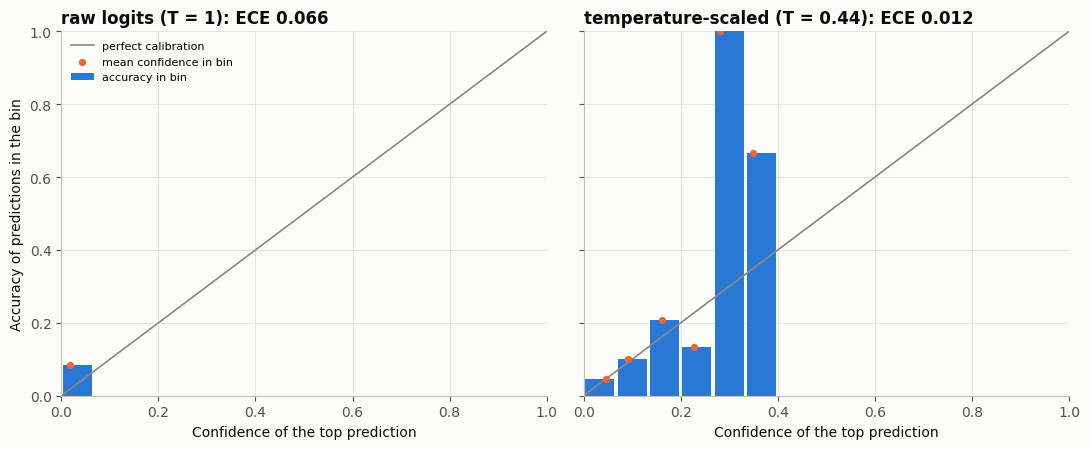

Takeaway: T = 0.44 sharpens the probabilities: the raw model was under-confident, and test ECE falls from 0.066 to 0.012 with top-1 unchanged at 8.3%.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (table_, ece, label) in zip(axes, ((before, ece_before, "raw logits (T = 1)"), (after, ece_after, f"temperature-scaled (T = {T:.2f})"))):
    centres = (table_.index + 0.5) / ECE_BINS
    ax.bar(centres, table_["accuracy"], width=0.9 / ECE_BINS, color=BLUE, label="accuracy in bin")
    ax.plot([0, 1], [0, 1], color=MUTED, linewidth=1.2, label="perfect calibration")
    ax.scatter(table_["confidence"], table_["accuracy"], color=ORANGE, s=18, zorder=3, label="mean confidence in bin")
    ax.set(title=f"{label}: ECE {ece:.3f}", xlabel="Confidence of the top prediction", xlim=(0, 1), ylim=(0, 1))
axes[0].set_ylabel("Accuracy of predictions in the bin")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
direction = "sharpens the probabilities: the raw model was under-confident" if T < 1 else "softens the probabilities: the raw model was over-confident"
takeaway(f"T = {T:.2f} {direction}, and test ECE {'falls' if ece_after < ece_before else 'rises'} from {ece_before:.3f} to {ece_after:.3f} with top-1 unchanged at "
         f"{(fp16_test.argmax(1) == y_test).mean():.1%}.")

The repository's shipped model went through the same step: T = 0.87 from validation, test ECE from 0.083 to 0.033 (`results/test_analysis/calibration.json`). Label smoothing (0.1 here) lowers a model's confidence during training, which is one reason a fitted T can come out below 1.

The FP16 model and a small metadata file with the labels and the temperature are saved to the notebook's output.

In [18]:
labels = {index: sign for sign, index in sign_map.items()}
meta = {"input": "landmarks", "input_shape": [None, NUM_FRAMES, FRAME_DIM], "output": "logits",
        "temperature": round(T, 4), "labels": [labels[i] for i in range(len(labels))]}
(WORK_DIR / "model_fp16_meta.json").write_text(json.dumps(meta))
for path in MODELS.values():
    if path.name != "model_fp16.onnx":
        path.unlink()  # Keep only the FP16 file in the output.
print(f"saved model_fp16.onnx ({(WORK_DIR / 'model_fp16.onnx').stat().st_size / 1e6:.1f} MB) and model_fp16_meta.json")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 7.2))
size_accuracy(ax1, size=140, fontsize=11)
ax1.set(title="Size against accuracy", xlabel="ONNX file size (MB)", ylabel="Test top-1 (4 unseen signers)")
centres = (after.index + 0.5) / ECE_BINS
ax2.bar(centres, after["accuracy"], width=0.9 / ECE_BINS, color=BLUE, label="accuracy (temperature-scaled)")
ax2.plot([0, 1], [0, 1], color=MUTED, linewidth=1.5, label="perfect calibration")
ax2.scatter(before["confidence"], before["accuracy"], color=ORANGE, s=40, zorder=3, label=f"raw model, ECE {ece_before:.3f}")
ax2.set(title=f"Reliability after T = {T:.2f}: ECE {ece_after:.3f}", xlabel="Confidence", ylabel="Accuracy", xlim=(0, 1), ylim=(0, 1))
ax2.legend(loc="upper left")
fig.suptitle("From PyTorch to the browser: ONNX, FP16, INT8 and temperature calibration", fontweight="bold", fontsize=16, x=0.02, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94))
save_cover(fig)
plt.close(fig)

saved model_fp16.onnx (6.9 MB) and model_fp16_meta.json


## 7. Loading the model in a browser

With onnxruntime-web, the saved FP16 file runs in a web page as it is. ManuVox does this in a Web Worker so the camera loop never waits for the classifier. A minimal version:

```js
import * as ort from "onnxruntime-web";

const meta = await (await fetch("model_fp16_meta.json")).json();
const session = await ort.InferenceSession.create("model_fp16.onnx", { executionProviders: ["wasm"] });

// frames: Float32Array of 32 x 120 values (59 landmarks x (x, y) + 2 hand-presence flags per frame),
// preprocessed exactly as in this series: shoulder-centred, mirrored to the right hand, resampled to 32 frames.
const { logits } = await session.run({ landmarks: new ort.Tensor("float32", frames, [1, 32, 120]) });
const scaled = Array.from(logits.data, (v) => v / meta.temperature);
const best = scaled.indexOf(Math.max(...scaled));
const p = Math.exp(scaled[best]) / scaled.reduce((sum, v) => sum + Math.exp(v), 0);  // softmax of the top sign
console.log(meta.labels[best], p);  // show it only when p clears a threshold chosen on validation data
```

The preprocessing has to match training exactly, which is where notebook 2's train-serve skew comes from.

## 8. What we found

In [19]:
display(Markdown(
    f"The exported ONNX graph matches PyTorch to within {np.abs(reference - exported).max():.1e} in the logits. "
    f"FP16 halves the file to {report.loc['fp16', 'size_mb']:.1f} MB and agrees with FP32 on {report.loc['fp16', 'agreement_with_fp32']:.1%} "
    f"of test clips ({pts(report.loc['fp16', 'delta_top1_pts'])} points top-1). "
    f"INT8 dynamic gives {report.loc['int8 dynamic', 'size_mb']:.1f} MB at {pts(report.loc['int8 dynamic', 'delta_top1_pts'])} points, "
    f"INT8 static {report.loc['int8 static', 'size_mb']:.1f} MB at {pts(report.loc['int8 static', 'delta_top1_pts'])}, and quantising "
    f"the input as well changes top-1 by {pts(report.loc['int8 static, full', 'delta_top1_pts'])} points. "
    f"On one thread of the {CPU}, p50 latency runs from {report['p50_ms'].min():.1f} to {report['p50_ms'].max():.1f} ms per sequence. "
    f"A temperature of {T:.2f} fitted on validation {'cuts' if ece_after < ece_before else 'raises'} test ECE from {ece_before:.3f} to {ece_after:.3f} without changing a single prediction."
))

The exported ONNX graph matches PyTorch to within 9.5e-07 in the logits. FP16 halves the file to 6.9 MB and agrees with FP32 on 100.0% of test clips (0.0 points top-1). INT8 dynamic gives 3.7 MB at -0.4 points, INT8 static 3.8 MB at +0.3, and quantising the input as well changes top-1 by -0.1 points. On one thread of the 11th Gen Intel(R) Core(TM) i3-1115G4 @ 3.00GHz, p50 latency runs from 1.8 to 22.4 ms per sequence. A temperature of 0.44 fitted on validation cuts test ECE from 0.066 to 0.012 without changing a single prediction.

### Limitations

- Latency is measured on the notebook's CPU through onnxruntime for Python; a laptop browser running WebAssembly is slower in absolute terms and can rank INT8 differently.
- The model trains for 40 epochs against notebook 4's 80; this notebook measures the differences between versions of one model.
- INT8 calibration uses MinMax ranges on 1,024 sequences. Other calibration methods (percentile, entropy) or quantisation-aware training could close part of the INT8 gap.
- ECE depends on the binning (15 equal-width bins here), and its bootstrap interval resamples clips, not signers.

### Ideas to try

- Run the same files in onnxruntime-web with the WebGPU backend and compare latency in your own browser.
- Try percentile calibration for INT8 static, or keep only the first projection layer in float32.
- Fit a separate temperature per signer group and see whether one global T is enough.

### The series

- [1. ASL Signs EDA: animating 94k landmark sequences](https://www.kaggle.com/code/swapnilshukla007/asl-signs-eda-animating-94k-landmark-sequences)
- [2. The hand-swap bug: measuring train-serve skew in MediaPipe sign recognition](https://www.kaggle.com/code/swapnilshukla007/the-hand-swap-bug-train-serve-skew-in-asl-models)
- [3. Why random splits overstate sign recognition accuracy](https://www.kaggle.com/code/swapnilshukla007/why-random-splits-overstate-sign-accuracy)
- [4. A CNN + Transformer hybrid for isolated sign recognition in PyTorch](https://www.kaggle.com/code/swapnilshukla007/cnn-transformer-hybrid-for-isolated-asl-signs)

If this helped, an upvote helps other people find it, and feedback in the comments is welcome.